This notebook converts the excel carpet plot into python to agree with the presentation theme. 

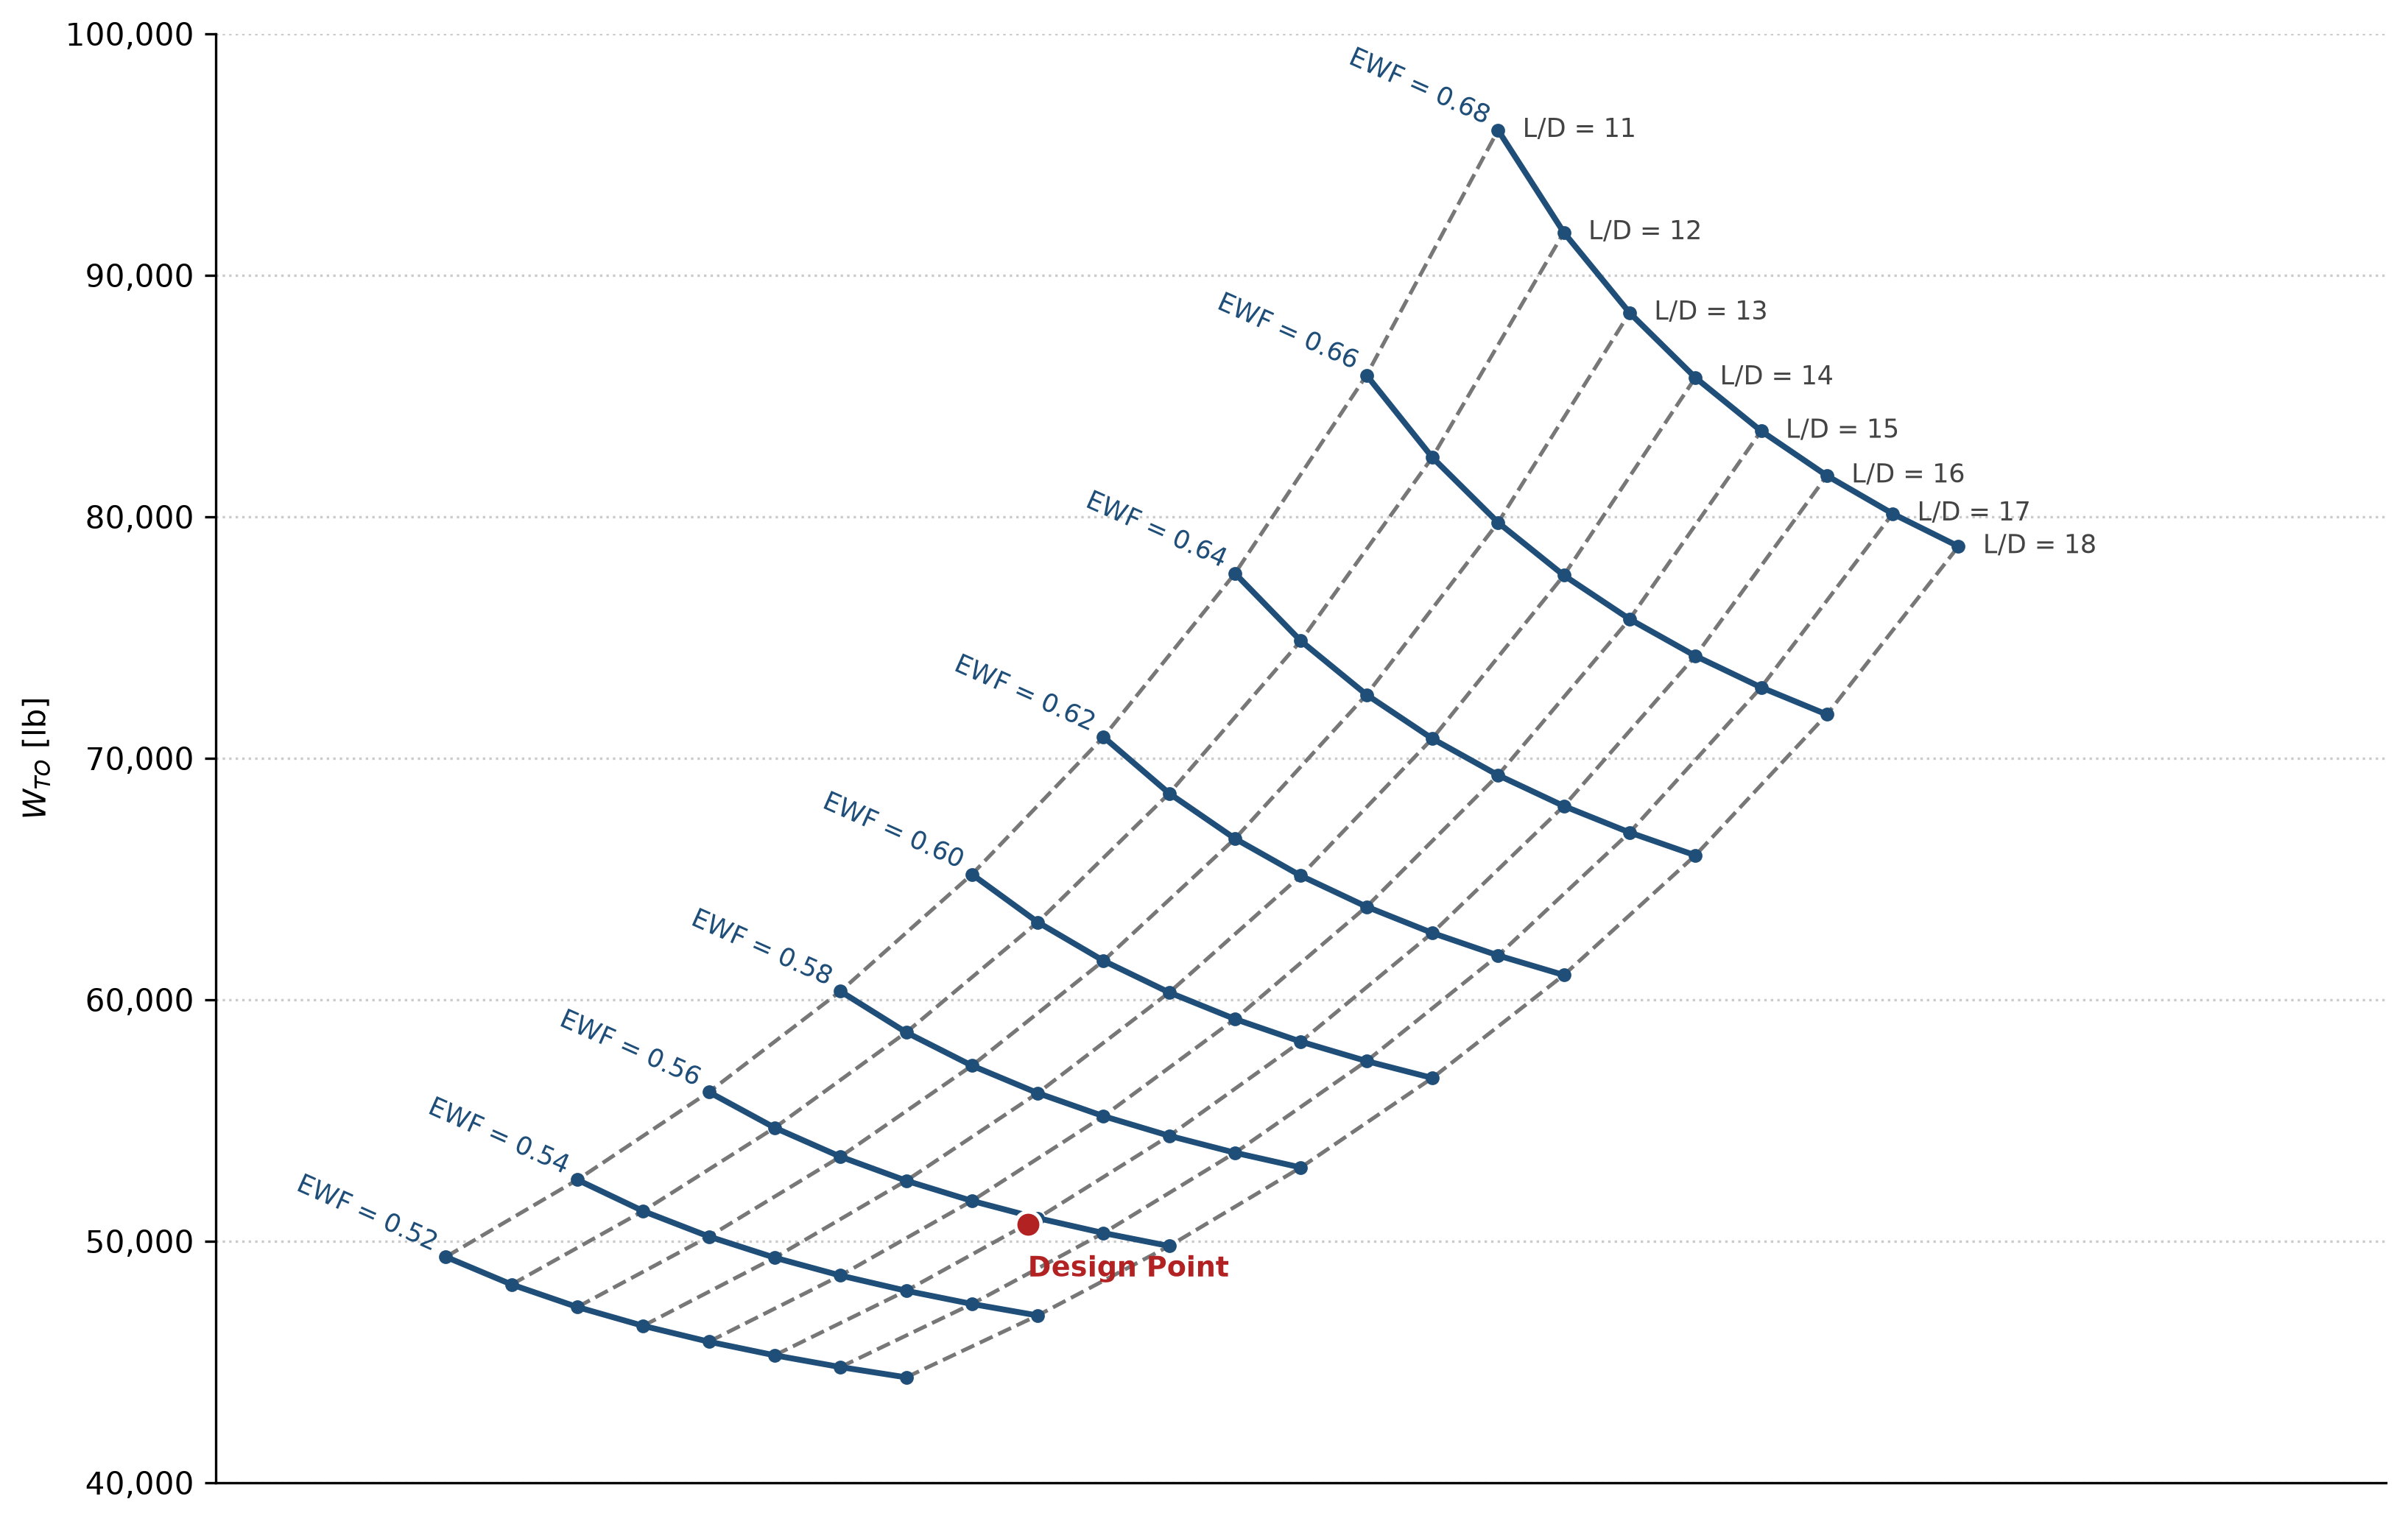

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# ----------------------------
# Design / sizing inputs
# ----------------------------
W_payload = 16250.0
R_design = 825.0                 # nmi; retained for documentation
LD_design = 16.0
W3_W2_design = 0.932134858       # cruise fraction from your sizing sheet

f_takeoff = 0.970
f_climb = 0.985
f_landing = 0.995
reserve_fraction = 0.06

# Carpet-grid values
LD = np.arange(11, 19, 1)
EWF = np.arange(0.52, 0.68, 0.02)

# ----------------------------
# Calculate W_TO grid
# ----------------------------
# Breguet exponent is proportional to 1 / (L/D).
# This preserves your stated cruise fraction at L/D = 16.
breguet_exponent = -LD_design * np.log(W3_W2_design)

# Each L/D value's cruise weight fraction: W3/W2
W3_W2 = np.exp(-breguet_exponent / LD)

# Complete mission weight fraction: W4/W0
W4_W0 = f_takeoff * f_climb * W3_W2 * f_landing

# Fuel that is consumed during the mission, excluding reserve
fuel_burn_fraction = 1 - W4_W0

# Installed fuel fraction, including the 6% reserve fuel
fuel_installed_fraction = fuel_burn_fraction / (1 - reserve_fraction)

# Rows correspond to L/D; columns correspond to EWF.
# W_TO = W_payload / (1 - EWF - Wf/W0)
W_TO = W_payload / (
    1
    - EWF[None, :]
    - fuel_installed_fraction[:, None]
)

# ----------------------------
# Carpet visual-coordinate map
# ----------------------------
# This is only a display transformation.
offset_per_LD = 0.01
X = EWF[None, :] + offset_per_LD * (LD[:, None] - LD[0])

# ----------------------------
# Plot isolines
# ----------------------------
fig, ax = plt.subplots(figsize=(11, 7), dpi=300)

# Constant-EWF isolines
for j, ewf in enumerate(EWF):
    ax.plot(
        X[:, j], W_TO[:, j],
        color="#1f4e79",
        linewidth=1.9,
        marker="o",
        markersize=3.5,
        zorder=3,
    )

    # EWF labels at left side of carpet
    ax.annotate(
        f"EWF = {ewf:.2f}",
        xy=(X[0, j], W_TO[0, j]),
        xytext=(-5, 0),
        textcoords="offset points",
        color="#1f4e79",
        fontsize=8.5,
        rotation=-24,
        rotation_mode="anchor",
        ha="right",
        va="bottom",
    )

# Constant-L/D isolines
for i, ld in enumerate(LD):
    ax.plot(
        X[i, :], W_TO[i, :],
        color="#777777",
        linewidth=1.25,
        linestyle="--",
        zorder=2,
    )

    ax.annotate(
        f"L/D = {ld}",
        xy=(X[i, -1], W_TO[i, -1]),
        xytext=(8, 0),
        textcoords="offset points",
        color="#444444",
        fontsize=8.5,
        ha="left",
        va="center",
    )

# ----------------------------
# Design reference point
# ----------------------------
W_TO_design = 50696.72136
EWF_design = 0.558498794
LD_design = 16.0

X_design = EWF_design + offset_per_LD * (LD_design - LD[0])

ax.scatter(
    X_design,
    W_TO_design,
    s=70,
    color="#b22222",
    edgecolor="white",
    linewidth=1.2,
    zorder=6,
)

ax.annotate(
    "Design Point",
    xy=(X_design, W_TO_design),
    xytext=(0, -10),
    textcoords="offset points",
    color="#b22222",
    fontsize=9,
    fontweight="semibold",
    ha="left",
    va="top",
)

# ----------------------------
# Formatting
# ----------------------------

ax.set_ylabel(r"$W_{TO}$ [lb]")
ax.set_xticks([])

ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(True, axis="y", linestyle=":", linewidth=0.8, alpha=0.65)
ax.spines[["top", "right"]].set_visible(False)

ax.set_xlim(X.min() - 0.035, X.max() + 0.065)
ax.set_ylim(40_000, 100_000)

fig.tight_layout()
fig.savefig("carpet_plot_corrected.png", dpi=300, bbox_inches="tight")
plt.show()